In [3]:
#@title Import Library & Gabungkan Dataset
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

os.makedirs("/reports/figures", exist_ok=True)

df_hf = pd.read_csv("hf_dataset.csv")
df_yt = pd.read_csv("youtube_comments_dataset.csv")

df = pd.concat([df_hf, df_yt], ignore_index=True)
df["id"] = range(1, len(df) + 1)

print("Ukuran dataset gabungan:", df.shape)
print("\nTipe data tiap kolom:\n", df.dtypes)
df.head()

Ukuran dataset gabungan: (11247, 5)

Tipe data tiap kolom:
 id                int64
text_caption     object
image_path       object
platform         object
label           float64
dtype: object


,id,text_caption,image_path,platform,label
0,1,🗿#starlightprincess #bahanswmu,image/image_1.jpg,TikTok,0.0
1,2,Tujuan dari filsafat pragmatis adalah berusaha...,image/image_2.jpg,TikTok,0.0
2,3,Pragmatis #timothyronald #akademicrypto #yfp ...,image/image_3.jpg,TikTok,0.0
3,4,Aku terlalu literal untuk kamu yg sesuai konte...,image/image_4.jpg,TikTok,0.0
4,5,How I built a restaurant website in 5 mins #we...,image/image_5.jpg,TikTok,0.0


In [4]:
#@title Cek Kondisi Data

# Cek missing values & duplikat
print("Missing values:\n", df.isnull().sum())
print("\nJumlah duplikat teks:", df["text_caption"].duplicated().sum())

# Cek proporsi kelas target & platform
print("\nJumlah per kelas (0 = Bukan Promosi, 1 = Promosi):")
print(df["label"].value_counts())
print("\nPersentase per kelas (%):")
print((df["label"].value_counts(normalize=True) * 100).round(2))

print("\nJumlah data per platform:")
print(df["platform"].value_counts())

# Cek data noise (URL, mention, dan panjang kata)
teks = df["text_caption"].astype(str)
print("\nTeks mengandung link (http):", teks.str.contains("http", case=False).sum())
print("Teks mengandung mention (@):", teks.str.contains("@").sum())

df["jumlah_kata"] = teks.str.split().str.len()
print("\nStatistik panjang kata:")
print(df["jumlah_kata"].describe())

Missing values:
 id              0
text_caption    0
image_path      0
platform        0
label           0
dtype: int64

Jumlah duplikat teks: 210

Jumlah per kelas (0 = Bukan Promosi, 1 = Promosi):
label
0.0    6381
1.0    4866
Name: count, dtype: int64

Persentase per kelas (%):
label
0.0    56.74
1.0    43.26
Name: proportion, dtype: float64

Jumlah data per platform:
platform
YouTube     6219
X           2167
TikTok      1442
Facebook    1419
Name: count, dtype: int64

Teks mengandung link (http): 2450
Teks mengandung mention (@): 742

Statistik panjang kata:
count    11247.000000
mean        27.449898
std         56.270347
min          1.000000
25%          6.000000
50%         11.000000
75%         26.000000
max       1371.000000
Name: jumlah_kata, dtype: float64


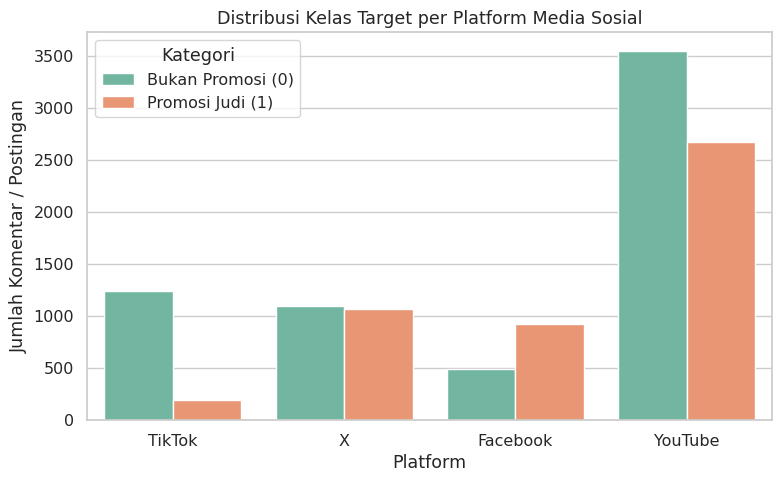

In [8]:
#@title Visualisasi 1 - Distribusi Kelas per Platform

df["kategori"] = df["label"].map({0.0: "Bukan Promosi (0)", 1.0: "Promosi Judi (1)"})

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="platform", hue="kategori", palette="Set2")
plt.title("Distribusi Kelas Target per Platform Media Sosial")
plt.xlabel("Platform")
plt.ylabel("Jumlah Komentar / Postingan")
plt.legend(title="Kategori")
plt.tight_layout()
plt.savefig("01_class_distribution_platform.png", dpi=150)
plt.show()

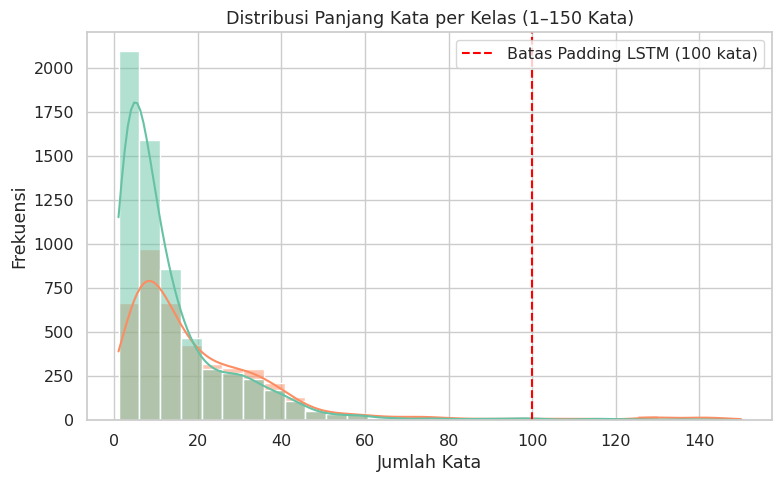

In [6]:
#@title Visualisasi 2 - Distribusi Panjang Kata

df_normal = df[df["jumlah_kata"] <= 150]

plt.figure(figsize=(8, 5))
sns.histplot(data=df_normal, x="jumlah_kata", hue="kategori", bins=30, kde=True, palette="Set2")
plt.axvline(100, color="red", linestyle="--", label="Batas Padding LSTM (100 kata)")
plt.title("Distribusi Panjang Kata per Kelas (1–150 Kata)")
plt.xlabel("Jumlah Kata")
plt.ylabel("Frekuensi")
plt.legend()
plt.tight_layout()
plt.savefig("02_word_length_distribution.png", dpi=150)
plt.show()

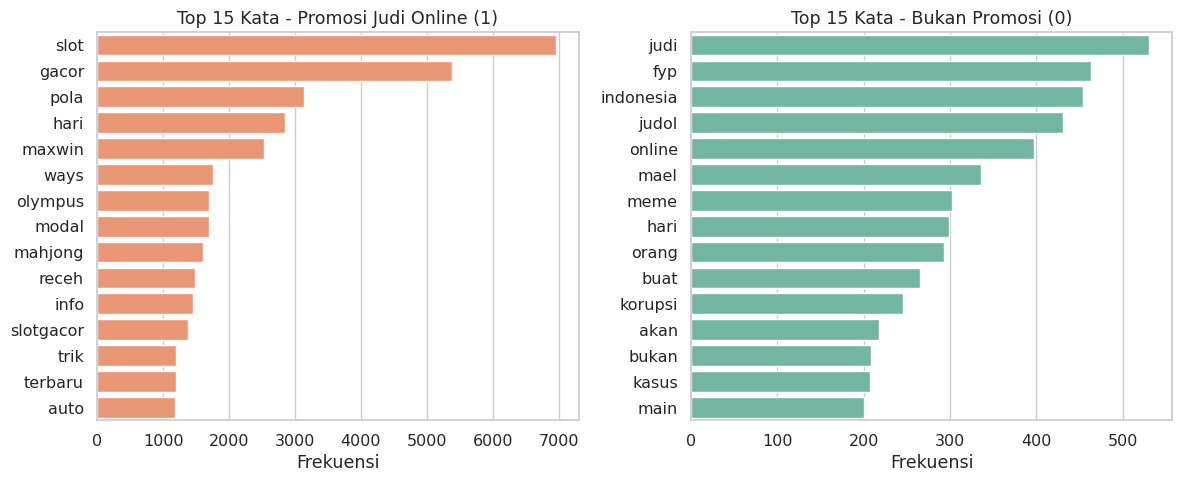

In [7]:
#@title Visualisasi 3 - Top 15 Kata Paling Sering Muncul

# Daftar kata hubung yang akan di abaikan
stopwords = {
    "yang", "dan", "di", "ke", "dari", "ini", "itu", "untuk", "dengan", "tidak",
    "yg", "nya", "ada", "aja", "kalo", "kalau", "gak", "ga", "ya", "bisa",
    "sudah", "udah", "mau", "apa", "sama", "tapi", "karena", "jadi", "juga",
    "lagi", "atau", "pada", "dalam", "kita", "kamu", "aku", "gua", "gw", "lu",
    "bang", "mas", "ni", "nih", "sih", "dong", "kan", "kok", "tuh", "saya"
}

def ambil_top_kata(series_teks, n=15):
    semua_kata = []
    for kalimat in series_teks.astype(str):
        for kata in kalimat.lower().split():
            # Ambil huruf saja (buang tanda baca/angka)
            kata_bersih = "".join(huruf for huruf in kata if huruf.isalpha())
            if len(kata_bersih) > 2 and kata_bersih not in stopwords:
                semua_kata.append(kata_bersih)
    return pd.DataFrame(Counter(semua_kata).most_common(n), columns=["kata", "jumlah"])

top_judi = ambil_top_kata(df[df["label"] == 1.0]["text_caption"])
top_aman = ambil_top_kata(df[df["label"] == 0.0]["text_caption"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=top_judi, x="jumlah", y="kata", ax=axes[0], color="#fc8d62")
axes[0].set_title("Top 15 Kata - Promosi Judi Online (1)")
axes[0].set_xlabel("Frekuensi")
axes[0].set_ylabel("")

sns.barplot(data=top_aman, x="jumlah", y="kata", ax=axes[1], color="#66c2a5")
axes[1].set_title("Top 15 Kata - Bukan Promosi (0)")
axes[1].set_xlabel("Frekuensi")
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("03_top_ngrams_comparison.png", dpi=150)
plt.show()